# RFMiD — subir el recall de `Disease_Risk` sin perder accuracy, F1 ni AUC

**Contexto médico.** Es un cribado: un falso negativo (paciente con riesgo que el modelo da por sano) es peor que un falso positivo. El objetivo es que el **recall de la clase enfermo** (sensibilidad) esté **cerca de 0.90 tanto en validación como en test**, manteniendo accuracy, F1 y AUC.

**Punto de partida:** el ResNet-152 ajustado con Optuna y entrenado con *letterbox* (sin recorte aleatorio) de `02.1_train_resnet152_nocrop.ipynb`, evaluado a umbral 0.5 y al umbral de Youden de validación (como en 02.1).

**Plan por etapas (se para en cuanto se cumple el objetivo):**
1. **Umbral de decisión elegido en validación**: el mayor umbral cuyo recall de validación sea ≥ objetivo (+ un pequeño margen). Es el método estándar y no cuesta nada; el AUC no cambia porque no se toca el modelo.
2. **TTA** (volteo horizontal y rotaciones ±10°) y **ensemble** (media de probabilidades) de los ResNet-152 ya entrenados, cada uno con su preprocesado. Miembros y variante final se eligen **solo con el AUC de validación**.
3. Búsqueda Optuna orientada a recall + reentrenamiento: solo si 1–2 no bastan (ver sección correspondiente).

**Reglas anti-fuga:** umbral, miembros del ensemble y variante final se deciden con **validación**; test solo se usa para informar las métricas finales (con IC 95 % bootstrap, 1000 remuestras, umbral fijo).

In [1]:
import json
import os
import sys
from pathlib import Path

# Localiza retina_clasificacion/ aunque el cwd del kernel sea el padre Retina/
_cwd = Path.cwd().resolve()
_candidates = [_cwd, *_cwd.parents]
if _cwd.is_dir():
    _candidates.extend(sorted(path for path in _cwd.iterdir() if path.is_dir()))
PROJECT_ROOT = next(
    directory
    for directory in _candidates
    if (directory / "src" / "config.py").is_file() and (directory / "requirements.txt").is_file()
)
sys.path = [entry for entry in sys.path if Path(entry or ".").resolve() != PROJECT_ROOT]
sys.path.insert(0, str(PROJECT_ROOT))
os.environ.setdefault("TORCH_HOME", str(PROJECT_ROOT / "artifacts" / "torch_cache"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import default_config
from src.data import build_split_dataframe
from src.evaluate import select_threshold_youden
from src.explain import compute_gradcam_samples, plot_gradcam_grid
from src.models_zoo import load_architecture_checkpoint
from src.recall_config import (
    BOOTSTRAP_RESAMPLES,
    BOOTSTRAP_SEED,
    FINAL_SUMMARY_PATH,
    PREDICTION_CACHE_DIR,
    RECALL_FIGURES_DIR,
    RECALL_GRADCAM_DIR,
    REFERENCE_MEMBER_NAME,
    TARGET_RECALL,
    VALIDATION_RECALL_MARGIN,
    existing_checkpoint_members,
)
from src.recall_optimization import (
    bootstrap_metric_differences,
    choose_ensemble_subset,
    compute_operating_point_metrics,
    rank_ensemble_subsets,
    select_threshold_for_recall,
    sweep_thresholds,
)
from src.recall_plots import plot_confusion_matrices, plot_roc_and_pr_curves, plot_threshold_sweep
from src.recall_report import build_summary_table, miss_rate_by_disease, summarize_operating_point
from src.train import get_device
from src.tta_inference import DEFAULT_TTA_VIEW_NAMES, average_views, get_member_view_probabilities

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
device = get_device()
validation_recall_goal = TARGET_RECALL + VALIDATION_RECALL_MARGIN
print(f"device={device} | recall objetivo={TARGET_RECALL} | objetivo en val (con margen)={validation_recall_goal:.2f}")

device=cpu | recall objetivo=0.9 | objetivo en val (con margen)=0.91


## 1. Datos y probabilidades de cada modelo

Se cargan las etiquetas de validación y test (134 sanos + 506 enfermos cada uno) y, para cada ResNet-152 ya entrenado, las probabilidades de P(riesgo) **por vista TTA**. Cada modelo se evalúa con **su** preprocesado (resize cuadrado los originales, letterbox los *nocrop*). La inferencia es lo caro en CPU, así que se guarda en `artifacts/recall/predictions/` y solo se calcula lo que falte (`scripts/precompute_recall_predictions.py` la deja precalculada).

In [2]:
config = default_config()
val_dataframe = build_split_dataframe(config.val_labels_csv, config.val_images_dir)
test_dataframe = build_split_dataframe(config.test_labels_csv, config.test_images_dir)
val_labels = val_dataframe["disease_risk"].to_numpy(dtype=float)
test_labels = test_dataframe["disease_risk"].to_numpy(dtype=float)
labels_by_split = {"val": val_labels, "test": test_labels}
print("val  :", int(val_labels.sum()), "enfermos /", int((1 - val_labels).sum()), "sanos")
print("test :", int(test_labels.sum()), "enfermos /", int((1 - test_labels).sum()), "sanos")

members = existing_checkpoint_members()
members_by_name = {member.name: member for member in members}
view_probabilities = {
    member.name: {
        "val": get_member_view_probabilities(member, "val", val_dataframe, PREDICTION_CACHE_DIR, device),
        "test": get_member_view_probabilities(member, "test", test_dataframe, PREDICTION_CACHE_DIR, device),
    }
    for member in members
}


def member_probabilities(use_tta: bool) -> dict[str, dict[str, np.ndarray]]:
    """{miembro: {split: P(riesgo)}} sin TTA (vista identity) o con la media de las vistas TTA."""
    view_names = DEFAULT_TTA_VIEW_NAMES if use_tta else ("identity",)
    return {
        name: {split: average_views(views[split], view_names) for split in ("val", "test")}
        for name, views in view_probabilities.items()
    }


plain_probabilities = member_probabilities(use_tta=False)
tta_probabilities = member_probabilities(use_tta=True)

member_auc_rows = []
for name in plain_probabilities:
    row = {"modelo": name, "preprocesado": members_by_name[name].preprocessing}
    for split in ("val", "test"):
        for label, source in (("sin TTA", plain_probabilities), ("TTA", tta_probabilities)):
            row[f"AUC {split} {label}"] = compute_operating_point_metrics(
                source[name][split], labels_by_split[split], 0.5
            )["auc"]
    member_auc_rows.append(row)
pd.DataFrame(member_auc_rows).set_index("modelo").round(4)

val  : 506 enfermos / 134 sanos
test : 506 enfermos / 134 sanos


,preprocesado,AUC val sin TTA,AUC val TTA,AUC test sin TTA,AUC test TTA
modelo,,,,,
ajustado_nocrop,letterbox,0.9375,0.9402,0.9677,0.9679
baseline_nocrop,letterbox,0.9400,0.9384,0.9608,0.9619
ajustado_original,random_crop,0.9312,0.9327,0.9640,0.9633
baseline_original,random_crop,0.9313,0.9355,0.9610,0.9629


## 2. Punto de partida (referencia)

Modelo `ajustado_nocrop` **sin TTA** con los dos umbrales de 02.1: 0.5 y el índice de Youden calculado en validación. Intervalos de confianza al 95 % por bootstrap sobre test (umbral fijo).

In [3]:
reference_probabilities = plain_probabilities[REFERENCE_MEMBER_NAME]
youden_threshold = select_threshold_youden(reference_probabilities["val"], val_labels)


def summarize_both_splits(configurations: dict[str, tuple[dict[str, np.ndarray], float]]):
    """Resúmenes por configuración: val sin IC y test con IC bootstrap. Umbral fijo (de val)."""
    val_summaries, test_summaries = {}, {}
    for name, (probabilities_by_split, threshold) in configurations.items():
        val_summaries[name] = summarize_operating_point(
            probabilities_by_split["val"], val_labels, threshold, BOOTSTRAP_RESAMPLES, BOOTSTRAP_SEED,
            with_intervals=False,
        )
        test_summaries[name] = summarize_operating_point(
            probabilities_by_split["test"], test_labels, threshold, BOOTSTRAP_RESAMPLES, BOOTSTRAP_SEED
        )
    return val_summaries, test_summaries


baseline_configurations = {
    "Referencia, umbral 0.5": (reference_probabilities, 0.5),
    "Referencia, umbral Youden (val)": (reference_probabilities, youden_threshold),
}
baseline_val_summaries, baseline_test_summaries = summarize_both_splits(baseline_configurations)
print("VALIDACIÓN")
display(build_summary_table(baseline_val_summaries))
print("TEST (IC 95 % bootstrap)")
display(build_summary_table(baseline_test_summaries))

VALIDACIÓN


,umbral,recall,specificity,precision,accuracy,f1,auc,TN / FP / FN / TP
configuración,,,,,,,,
"Referencia, umbral 0.5",0.500,0.838,0.896,0.968,0.850,0.898,0.938,120 / 14 / 82 / 424
"Referencia, umbral Youden (val)",0.545,0.824,0.948,0.983,0.850,0.897,0.938,127 / 7 / 89 / 417


TEST (IC 95 % bootstrap)


,umbral,recall,specificity,precision,accuracy,f1,auc,TN / FP / FN / TP
configuración,,,,,,,,
"Referencia, umbral 0.5",0.500,"0.868 [0.836, 0.893]","0.955 [0.913, 0.986]","0.987 [0.975, 0.996]","0.886 [0.859, 0.908]","0.923 [0.904, 0.939]","0.968 [0.953, 0.978]",128 / 6 / 67 / 439
"Referencia, umbral Youden (val)",0.545,"0.850 [0.817, 0.878]","0.963 [0.924, 0.992]","0.989 [0.977, 0.998]","0.873 [0.845, 0.898]","0.914 [0.894, 0.932]","0.968 [0.953, 0.978]",129 / 5 / 76 / 430


## 3. Etapa 1 — umbral elegido en validación

El recall de validación solo baja al subir el umbral y la especificidad solo sube. Por eso el **mayor umbral con recall de validación ≥ objetivo** es el que más especificidad conserva. Se apunta a `objetivo + margen` (0.91) porque el recall de test fluctúa unos puntos respecto al de validación (506 positivos). La curva de validación es la que decide; la de test se muestra solo a título informativo con el mismo umbral.

Umbral etapa 1 (elegido en validación) = 0.3650


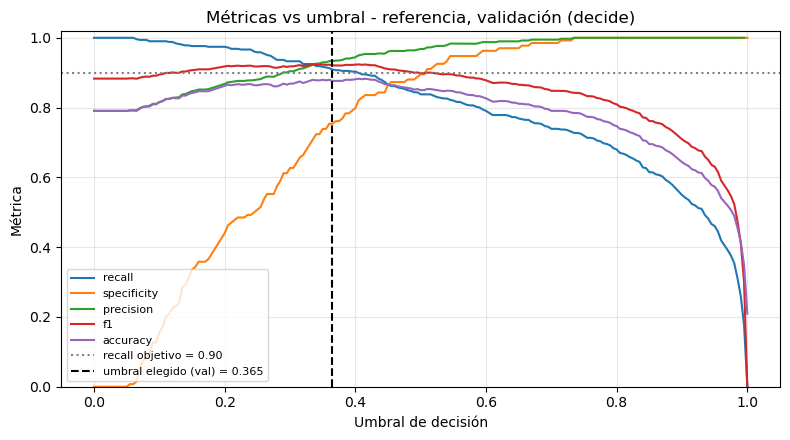

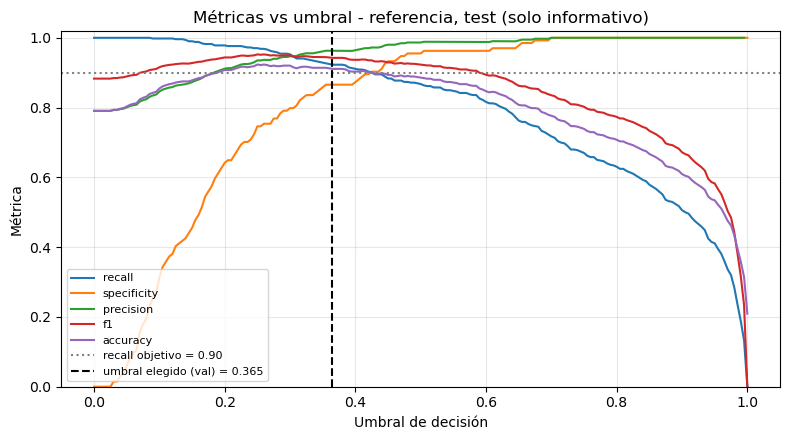

In [4]:
stage1_threshold = select_threshold_for_recall(reference_probabilities["val"], val_labels, validation_recall_goal)
print(f"Umbral etapa 1 (elegido en validación) = {stage1_threshold:.4f}")

RECALL_FIGURES_DIR.mkdir(parents=True, exist_ok=True)
for split_name, title_suffix in (("val", "validación (decide)"), ("test", "test (solo informativo)")):
    sweep_table = sweep_thresholds(reference_probabilities[split_name], labels_by_split[split_name])
    plot_threshold_sweep(
        sweep_table, stage1_threshold, TARGET_RECALL,
        title=f"Métricas vs umbral - referencia, {title_suffix}",
        save_path=RECALL_FIGURES_DIR / f"threshold_sweep_reference_{split_name}.png",
    )
    plt.show()

## 4. Etapa 2 — TTA y ensemble

- **TTA**: se promedian las probabilidades de 4 vistas deterministas (original, volteo horizontal, rotación +10° y −10° con relleno negro).
- **Ensemble**: media de probabilidades de un subconjunto de los 4 ResNet-152. Con 4 modelos se evalúan **los 15 subconjuntos** y se elige el de mayor AUC de **validación**; a igualdad práctica (diferencia < 0.002, ruido con 640 imágenes) se prefiere el más grande, que es más estable.
- Entre las 4 variantes (referencia, referencia+TTA, ensemble, ensemble+TTA) se elige la de **mayor AUC de validación**. Test no interviene.

In [5]:
ranking_without_tta = rank_ensemble_subsets({n: p["val"] for n, p in plain_probabilities.items()}, val_labels)
ranking_with_tta = rank_ensemble_subsets({n: p["val"] for n, p in tta_probabilities.items()}, val_labels)
print("Top 5 subconjuntos SIN TTA (AUC val)")
display(ranking_without_tta.head(5))
print("Top 5 subconjuntos CON TTA (AUC val)")
display(ranking_with_tta.head(5))

ensemble_members_without_tta = choose_ensemble_subset(ranking_without_tta)
ensemble_members_with_tta = choose_ensemble_subset(ranking_with_tta)


def averaged_over(source: dict, member_names: tuple[str, ...]) -> dict[str, np.ndarray]:
    return {split: np.mean([source[name][split] for name in member_names], axis=0) for split in ("val", "test")}


candidate_definitions = {
    "A: referencia": (plain_probabilities, (REFERENCE_MEMBER_NAME,), False),
    "B: referencia + TTA": (tta_probabilities, (REFERENCE_MEMBER_NAME,), True),
    "C: ensemble": (plain_probabilities, ensemble_members_without_tta, False),
    "D: ensemble + TTA": (tta_probabilities, ensemble_members_with_tta, True),
}
candidate_probabilities = {
    name: averaged_over(source, member_names)
    for name, (source, member_names, _) in candidate_definitions.items()
}

selection_rows = []
for name, probabilities_by_split in candidate_probabilities.items():
    candidate_threshold = select_threshold_for_recall(probabilities_by_split["val"], val_labels, validation_recall_goal)
    val_metrics = compute_operating_point_metrics(probabilities_by_split["val"], val_labels, candidate_threshold)
    selection_rows.append(
        {
            "variante": name,
            "miembros": ", ".join(candidate_definitions[name][1]),
            "AUC val": val_metrics["auc"],
            "umbral": candidate_threshold,
            "recall val": val_metrics["recall"],
            "especificidad val": val_metrics["specificity"],
            "F1 val": val_metrics["f1"],
            "accuracy val": val_metrics["accuracy"],
        }
    )
selection_table = pd.DataFrame(selection_rows).set_index("variante")
display(selection_table.round(4))

chosen_candidate_name = selection_table["AUC val"].idxmax()
_, chosen_member_names, chosen_uses_tta = candidate_definitions[chosen_candidate_name]
chosen_probabilities = candidate_probabilities[chosen_candidate_name]
chosen_threshold = float(selection_table.loc[chosen_candidate_name, "umbral"])
print(f"\nVariante elegida con VALIDACIÓN: {chosen_candidate_name} | miembros={chosen_member_names} | umbral={chosen_threshold:.4f}")

Top 5 subconjuntos SIN TTA (AUC val)


,miembros,n_miembros,val_auc
0,"(ajustado_nocrop, baseline_nocrop, ajustado_original, baseline_original)",4,0.943351
1,"(baseline_nocrop, ajustado_original, baseline_original)",3,0.943071
2,"(ajustado_nocrop, baseline_nocrop, ajustado_original)",3,0.942997
3,"(ajustado_nocrop, baseline_nocrop)",2,0.942909
4,"(ajustado_nocrop, baseline_nocrop, baseline_original)",3,0.942850


Top 5 subconjuntos CON TTA (AUC val)


,miembros,n_miembros,val_auc
0,"(ajustado_nocrop, baseline_nocrop)",2,0.944000
1,"(ajustado_nocrop, baseline_nocrop, ajustado_original, baseline_original)",4,0.943986
2,"(ajustado_nocrop, baseline_nocrop, baseline_original)",3,0.943882
3,"(ajustado_nocrop, baseline_nocrop, ajustado_original)",3,0.943587
4,"(ajustado_nocrop, ajustado_original, baseline_original)",3,0.942909


,miembros,AUC val,umbral,recall val,especificidad val,F1 val,accuracy val
variante,,,,,,,
A: referencia,ajustado_nocrop,0.9375,0.3650,0.9111,0.7537,0.9220,0.8781
B: referencia + TTA,ajustado_nocrop,0.9402,0.3811,0.9111,0.7537,0.9220,0.8781
C: ensemble,"ajustado_nocrop, baseline_nocrop, ajustado_original, baseline_original",0.9434,0.4016,0.9111,0.8060,0.9285,0.8891
D: ensemble + TTA,"ajustado_nocrop, baseline_nocrop, ajustado_original, baseline_original",0.9440,0.3993,0.9111,0.7761,0.9248,0.8828



Variante elegida con VALIDACIÓN: D: ensemble + TTA | miembros=('ajustado_nocrop', 'baseline_nocrop', 'ajustado_original', 'baseline_original') | umbral=0.3993


## 5. Etapa 3 — Optuna orientada a recall

Solo estaba prevista si las etapas 1–2 no alcanzaban el recall ≈ 0.90 sin perjudicar F1, accuracy o AUC. La comprobación está en la sección siguiente: **si el objetivo se cumple en validación y en test sin pérdidas apreciables, no se lanza la búsqueda** (sería coste de CPU sin beneficio justificable y más riesgo de sobreajustar la validación de 640 imágenes). La celda calcula esa condición explícitamente.

In [6]:
final_val_metrics = compute_operating_point_metrics(chosen_probabilities["val"], val_labels, chosen_threshold)
final_test_metrics = compute_operating_point_metrics(chosen_probabilities["test"], test_labels, chosen_threshold)
reference_test_metrics = compute_operating_point_metrics(reference_probabilities["test"], test_labels, 0.5)

target_met = (
    final_val_metrics["recall"] >= TARGET_RECALL - 0.005
    and final_test_metrics["recall"] >= TARGET_RECALL - 0.005
)
no_metric_loss = all(
    final_test_metrics[name] >= reference_test_metrics[name] - 0.005 for name in ("accuracy", "f1", "auc")
)
print(f"Recall val={final_val_metrics['recall']:.3f} | recall test={final_test_metrics['recall']:.3f}")
print(f"¿Objetivo de recall cumplido en val y test? {target_met}")
print(f"¿Accuracy, F1 y AUC de test sin pérdida (> -0.005 vs referencia a 0.5)? {no_metric_loss}")
stage3_needed = not (target_met and no_metric_loss)
print("Etapa 3 (Optuna) necesaria:", stage3_needed)

Recall val=0.911 | recall test=0.929
¿Objetivo de recall cumplido en val y test? True
¿Accuracy, F1 y AUC de test sin pérdida (> -0.005 vs referencia a 0.5)? True
Etapa 3 (Optuna) necesaria: False


## 6. Tabla final en TEST (umbral 0.5 / Youden vs mejorado)

Todas las filas usan umbrales fijados con validación; test solo informa. Entre corchetes, IC 95 % por bootstrap (1000 remuestras). La penúltima fila aísla el efecto del umbral; la última es el sistema final.

In [7]:
final_label = f"FINAL: {chosen_candidate_name} + umbral val"
final_configurations = {
    **baseline_configurations,
    "Etapa 1: referencia + umbral val (recall objetivo)": (reference_probabilities, stage1_threshold),
    final_label: (chosen_probabilities, chosen_threshold),
    # Sensibilidad al margen: mismo sistema pero con el recall de val exactamente >= 0.90
    f"Variante sin margen (recall val >= {TARGET_RECALL:.2f})": (
        chosen_probabilities,
        select_threshold_for_recall(chosen_probabilities["val"], val_labels, TARGET_RECALL),
    ),
}
final_val_summaries, final_test_summaries = summarize_both_splits(final_configurations)

print("TEST (IC 95 % bootstrap)")
final_test_table = build_summary_table(final_test_summaries)
display(final_test_table)
print("VALIDACIÓN (la que decide)")
display(build_summary_table(final_val_summaries))

# Bootstrap pareado: final vs referencia a 0.5 (diferencia de cada métrica con IC 95 %)
paired_differences = bootstrap_metric_differences(
    chosen_probabilities["test"], chosen_threshold,
    reference_probabilities["test"], 0.5,
    test_labels, n_resamples=BOOTSTRAP_RESAMPLES, seed=BOOTSTRAP_SEED,
)
difference_table = pd.DataFrame(
    {
        name: {"diferencia": diff, "IC95 inf": low, "IC95 sup": high}
        for name, (diff, low, high) in paired_differences.items()
    }
).T.round(4)
print("Diferencia FINAL - referencia(0.5) en test, bootstrap pareado")
display(difference_table)

TEST (IC 95 % bootstrap)


,umbral,recall,specificity,precision,accuracy,f1,auc,TN / FP / FN / TP
configuración,,,,,,,,
"Referencia, umbral 0.5",0.500,"0.868 [0.836, 0.893]","0.955 [0.913, 0.986]","0.987 [0.975, 0.996]","0.886 [0.859, 0.908]","0.923 [0.904, 0.939]","0.968 [0.953, 0.978]",128 / 6 / 67 / 439
"Referencia, umbral Youden (val)",0.545,"0.850 [0.817, 0.878]","0.963 [0.924, 0.992]","0.989 [0.977, 0.998]","0.873 [0.845, 0.898]","0.914 [0.894, 0.932]","0.968 [0.953, 0.978]",129 / 5 / 76 / 430
Etapa 1: referencia + umbral val (recall objetivo),0.365,"0.923 [0.898, 0.944]","0.866 [0.807, 0.916]","0.963 [0.946, 0.977]","0.911 [0.887, 0.931]","0.942 [0.927, 0.956]","0.968 [0.953, 0.978]",116 / 18 / 39 / 467
FINAL: D: ensemble + TTA + umbral val,0.399,"0.929 [0.906, 0.951]","0.881 [0.824, 0.931]","0.967 [0.950, 0.981]","0.919 [0.897, 0.939]","0.948 [0.933, 0.961]","0.971 [0.958, 0.981]",118 / 16 / 36 / 470
Variante sin margen (recall val >= 0.90),0.416,"0.913 [0.888, 0.936]","0.888 [0.832, 0.936]","0.969 [0.952, 0.982]","0.908 [0.884, 0.930]","0.940 [0.924, 0.954]","0.971 [0.958, 0.981]",119 / 15 / 44 / 462


VALIDACIÓN (la que decide)


,umbral,recall,specificity,precision,accuracy,f1,auc,TN / FP / FN / TP
configuración,,,,,,,,
"Referencia, umbral 0.5",0.500,0.838,0.896,0.968,0.850,0.898,0.938,120 / 14 / 82 / 424
"Referencia, umbral Youden (val)",0.545,0.824,0.948,0.983,0.850,0.897,0.938,127 / 7 / 89 / 417
Etapa 1: referencia + umbral val (recall objetivo),0.365,0.911,0.754,0.933,0.878,0.922,0.938,101 / 33 / 45 / 461
FINAL: D: ensemble + TTA + umbral val,0.399,0.911,0.776,0.939,0.883,0.925,0.944,104 / 30 / 45 / 461
Variante sin margen (recall val >= 0.90),0.416,0.901,0.813,0.948,0.883,0.924,0.944,109 / 25 / 50 / 456


Diferencia FINAL - referencia(0.5) en test, bootstrap pareado


,diferencia,IC95 inf,IC95 sup
recall,0.0613,0.0428,0.0835
specificity,-0.0746,-0.1221,-0.0365
precision,-0.0194,-0.0330,-0.0088
accuracy,0.0328,0.0141,0.0531
f1,0.0243,0.0119,0.0389
auc,0.0029,-0.0021,0.0086


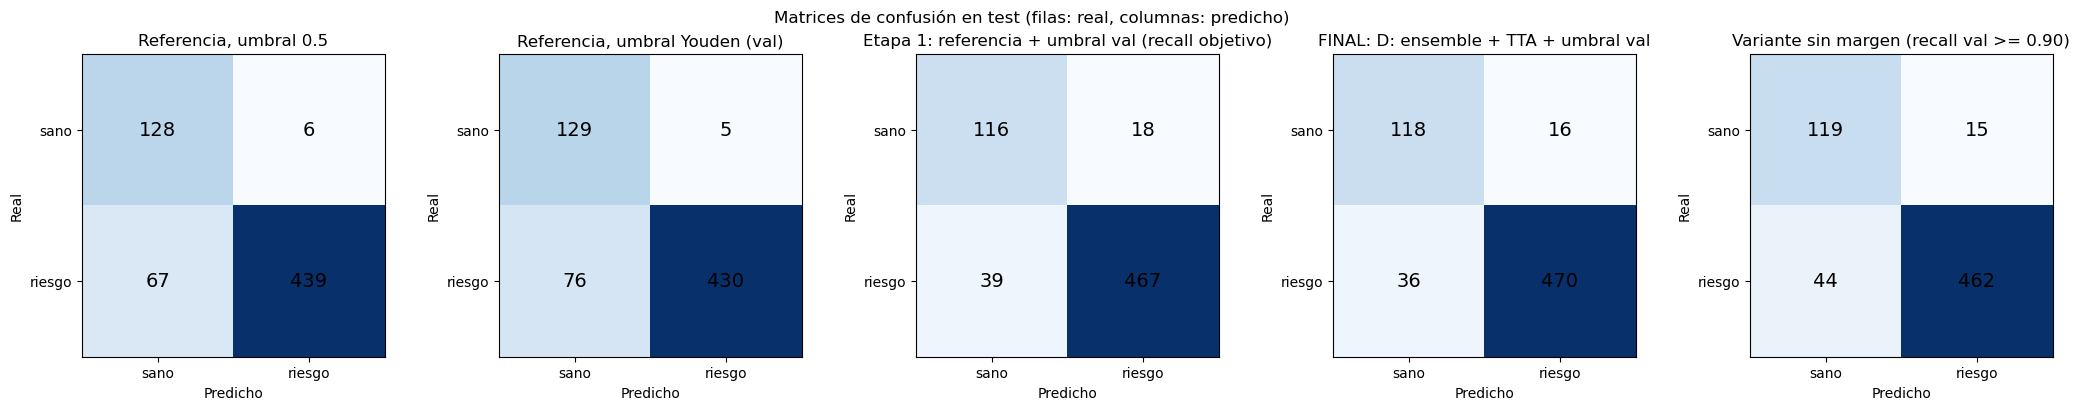

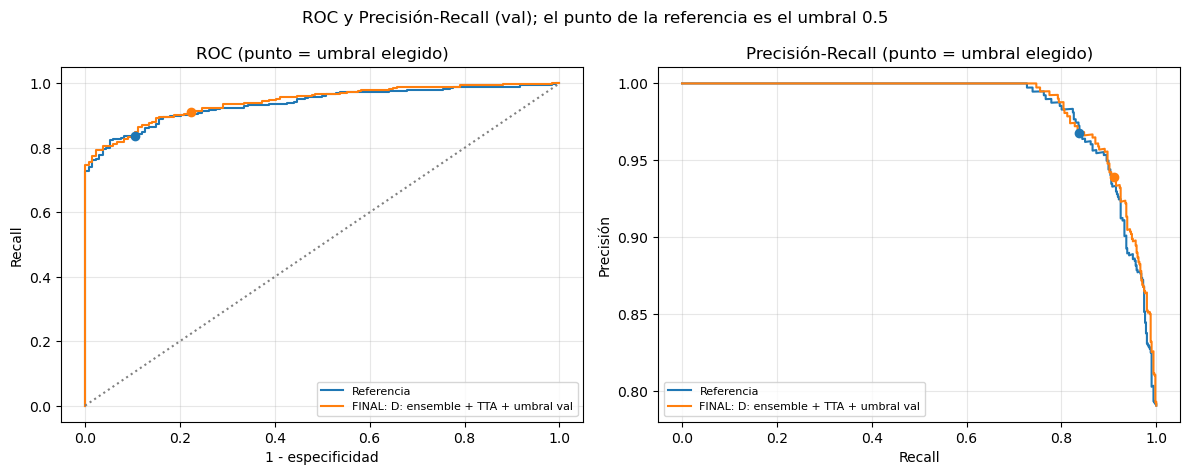

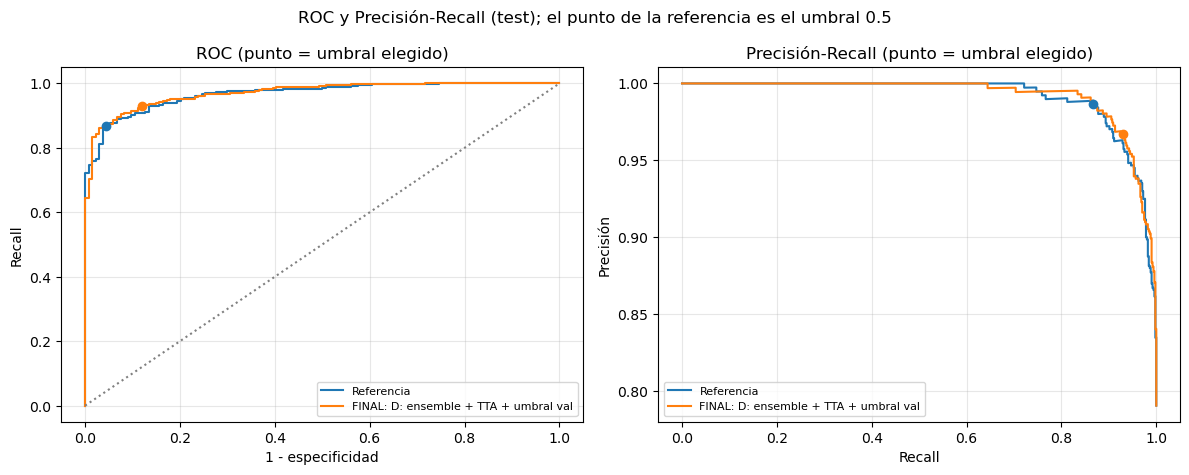

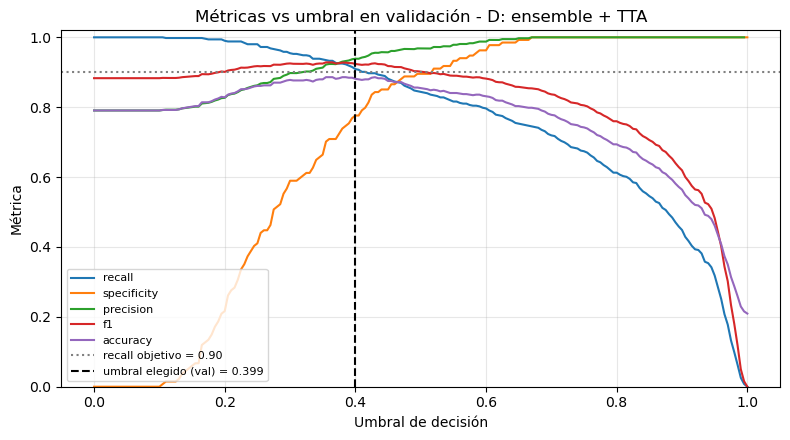

In [8]:
plot_confusion_matrices(
    {name: summary["confusion_matrix"] for name, summary in final_test_summaries.items()},
    title="Matrices de confusión en test (filas: real, columnas: predicho)",
    save_path=RECALL_FIGURES_DIR / "confusion_matrices_test.png",
)
plt.show()

for split_name, split_labels in labels_by_split.items():
    split_summaries = final_val_summaries if split_name == "val" else final_test_summaries
    plot_roc_and_pr_curves(
        curves={
            "Referencia": (reference_probabilities[split_name], split_labels),
            final_label: (chosen_probabilities[split_name], split_labels),
        },
        operating_points={
            "Referencia": (0.5, split_summaries["Referencia, umbral 0.5"]["recall"],
                           split_summaries["Referencia, umbral 0.5"]["specificity"]),
            final_label: (chosen_threshold, split_summaries[final_label]["recall"],
                          split_summaries[final_label]["specificity"]),
        },
        title=f"ROC y Precisión-Recall ({split_name}); el punto de la referencia es el umbral 0.5",
        save_path=RECALL_FIGURES_DIR / f"roc_pr_{split_name}.png",
    )
    plt.show()

final_sweep = sweep_thresholds(chosen_probabilities["val"], val_labels)
plot_threshold_sweep(
    final_sweep, chosen_threshold, TARGET_RECALL,
    title=f"Métricas vs umbral en validación - {chosen_candidate_name}",
    save_path=RECALL_FIGURES_DIR / "threshold_sweep_final_val.png",
)
plt.show()

## 7. Falsos negativos que quedan (test)

Se analiza qué enfermos sigue dejando pasar el sistema final: cuántos son, si los pierden todos los modelos, qué enfermedades concretas (columnas de RFMiD) concentran los fallos y qué mira la red en los más confiados (Grad-CAM del ResNet-152 `ajustado_nocrop`, con el **mismo letterbox** que usó para entrenar; la probabilidad impresa es la de ese modelo, no la del ensemble).

In [9]:
final_predictions = chosen_probabilities["test"] >= chosen_threshold
false_negative_mask = (test_labels == 1) & ~final_predictions
false_negative_indices = np.flatnonzero(false_negative_mask)
print(f"Falsos negativos en test: {len(false_negative_indices)} de {int(test_labels.sum())} enfermos")

# ¿Los falla cada miembro individualmente al mismo umbral por separado? (solo informativo)
member_rows = []
for name in plain_probabilities:
    member_threshold = select_threshold_for_recall(plain_probabilities[name]["val"], val_labels, validation_recall_goal)
    member_metrics = compute_operating_point_metrics(plain_probabilities[name]["test"], test_labels, member_threshold)
    member_rows.append(
        {"miembro": name, "umbral (val)": member_threshold, "FN test": member_metrics["confusion_matrix"][1][0],
         "recall test": member_metrics["recall"], "especificidad test": member_metrics["specificity"]}
    )
print("Cada miembro por separado (sin TTA, con su propio umbral elegido en val): los FN solo son comparables a igual especificidad")
display(pd.DataFrame(member_rows).set_index("miembro").round(3))

false_negative_probabilities = chosen_probabilities["test"][false_negative_indices]
print(
    f"P(riesgo) de los FN del sistema final: mediana={np.median(false_negative_probabilities):.3f}, "
    f"mínima={false_negative_probabilities.min():.3f}, máxima={false_negative_probabilities.max():.3f} "
    f"(umbral={chosen_threshold:.3f})"
)
near_misses = int((false_negative_probabilities >= 0.75 * chosen_threshold).sum())
print(f"FN 'por poco' (P >= 75 % del umbral): {near_misses}")

miss_table = miss_rate_by_disease(config.test_labels_csv, chosen_probabilities["test"], chosen_threshold)
display(miss_table)

Falsos negativos en test: 36 de 506 enfermos
Cada miembro por separado (sin TTA, con su propio umbral elegido en val): los FN solo son comparables a igual especificidad


,umbral (val),FN test,recall test,especificidad test
miembro,,,,
ajustado_nocrop,0.365,39,0.923,0.866
baseline_nocrop,0.402,47,0.907,0.851
ajustado_original,0.375,51,0.899,0.888
baseline_original,0.380,28,0.945,0.836


P(riesgo) de los FN del sistema final: mediana=0.294, mínima=0.154, máxima=0.398 (umbral=0.399)
FN 'por poco' (P >= 75 % del umbral): 17


,enfermedad,casos,falsos_negativos,tasa_fn
0,ERM,5,1,0.200
1,ODC,91,17,0.187
2,DN,46,7,0.152
3,ODE,17,2,0.118
4,ODP,24,2,0.083
5,CSR,13,1,0.077
6,DR,124,3,0.024
7,TSLN,53,1,0.019
8,MH,104,2,0.019
9,ARMD,31,0,0.000


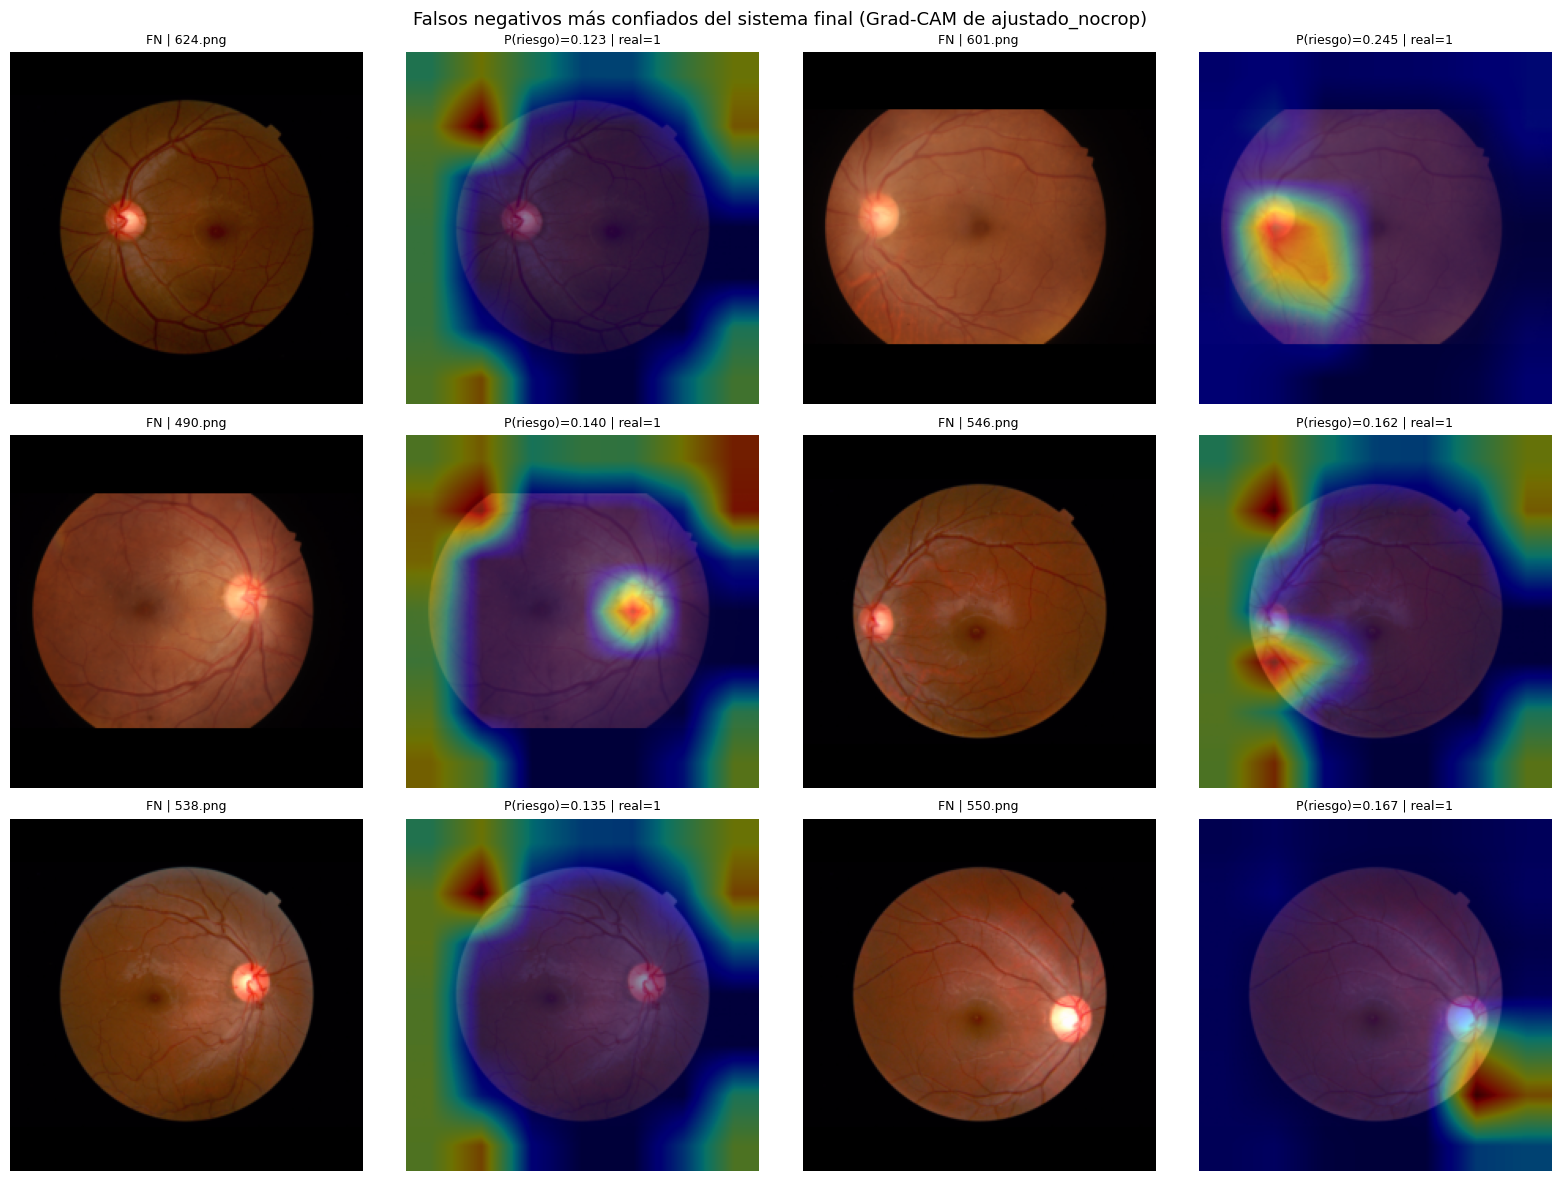

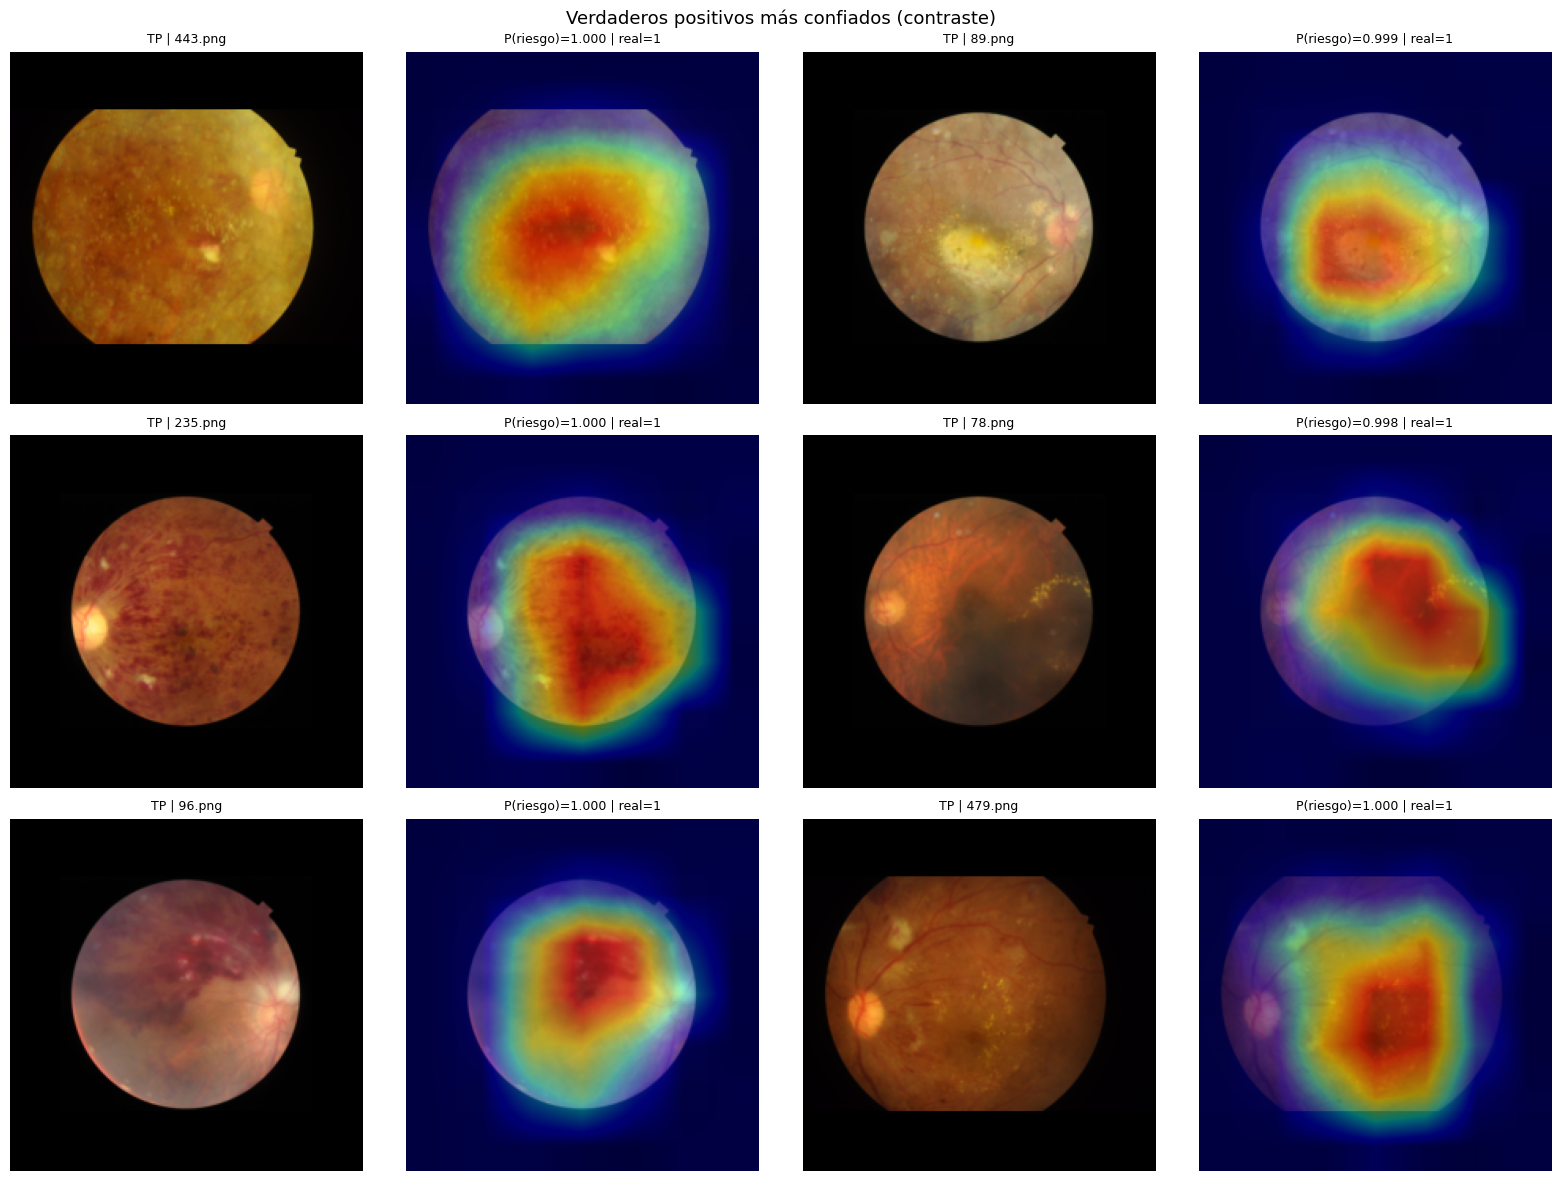

In [10]:
reference_member = members_by_name[REFERENCE_MEMBER_NAME]
gradcam_model = load_architecture_checkpoint("resnet152", reference_member.checkpoint_path, device)
gradcam_samples = compute_gradcam_samples(
    gradcam_model,
    test_dataframe,
    chosen_probabilities["test"],
    test_labels,
    threshold=chosen_threshold,
    image_size=reference_member.image_size,
    examples_per_group=6,
    preprocessing=reference_member.preprocessing,
)
for group, group_title in (
    ("FN", "Falsos negativos más confiados del sistema final (Grad-CAM de ajustado_nocrop)"),
    ("TP", "Verdaderos positivos más confiados (contraste)"),
):
    group_samples = [sample for sample in gradcam_samples if sample["group"] == group]
    plot_gradcam_grid(group_samples, title=group_title, save_path=RECALL_GRADCAM_DIR / f"final_{group}.png")
    plt.show()

## 8. Resumen guardado

In [11]:
def metrics_without_matrix(summary: dict) -> dict:
    return {name: value for name, value in summary.items() if name != "confusion_matrix"} | {
        "confusion_matrix_TN_FP_FN_TP": [
            summary["confusion_matrix"][0][0], summary["confusion_matrix"][0][1],
            summary["confusion_matrix"][1][0], summary["confusion_matrix"][1][1],
        ]
    }


final_summary = {
    "method": "umbral recall-objetivo elegido en validación"
    + (" + ensemble" if len(chosen_member_names) > 1 else "")
    + (" + TTA" if chosen_uses_tta else ""),
    "chosen_variant": chosen_candidate_name,
    "ensemble_members": list(chosen_member_names),
    "member_preprocessing": {name: members_by_name[name].preprocessing for name in chosen_member_names},
    "tta_views": list(DEFAULT_TTA_VIEW_NAMES) if chosen_uses_tta else ["identity"],
    "target_recall": TARGET_RECALL,
    "validation_recall_margin": VALIDATION_RECALL_MARGIN,
    "decision_threshold": chosen_threshold,
    "threshold_selected_on": "validation only",
    "bootstrap": {"resamples": BOOTSTRAP_RESAMPLES, "confidence_level": 0.95, "seed": BOOTSTRAP_SEED},
    "val_metrics": {name: metrics_without_matrix(s) for name, s in final_val_summaries.items()},
    "test_metrics": {name: metrics_without_matrix(s) for name, s in final_test_summaries.items()},
    "paired_difference_final_minus_reference_0.5_test": {
        name: {"difference": diff, "ci95": [low, high]} for name, (diff, low, high) in paired_differences.items()
    },
    "false_negatives_test": int(len(false_negative_indices)),
    "optuna_stage_run": False,
    "optuna_stage_needed": stage3_needed,
    "notes": "Etapa 3 (Optuna + reentrenamiento) no ejecutada en este notebook; ver optuna_stage_needed.",
}
FINAL_SUMMARY_PATH.parent.mkdir(parents=True, exist_ok=True)
FINAL_SUMMARY_PATH.write_text(json.dumps(final_summary, indent=2, ensure_ascii=False), encoding="utf-8")
print("Guardado en", FINAL_SUMMARY_PATH)

Guardado en C:\Users\Xabat Arin\Desktop\kaggle\Retina\artifacts\recall\final_summary.json


## 9. Conclusión

**¿Se alcanzó el recall ≈ 0.90? Sí, en validación y en test, sin tocar ni reentrenar ningún modelo.** La etapa 3 (Optuna + reentrenamiento) **no se ejecutó** porque las etapas 1–2 ya cumplían el objetivo (ver la celda de comprobación); lanzarla habría costado horas de CPU y más riesgo de sobreajustar una validación de solo 640 imágenes (134 sanos).

**Método final** (todo elegido con validación): media de probabilidades de los 4 ResNet-152 (cada uno con su preprocesado) con TTA de 4 vistas (original, volteo horizontal, rotación ±10°), y umbral de decisión **0.399** = mayor umbral con recall de validación ≥ 0.91 (objetivo 0.90 + 0.01 de margen).

**Resultado en test** (IC 95 % bootstrap, umbral fijado en validación), frente a la referencia (`ajustado_nocrop`, umbral 0.5):

| | Referencia (0.5) | **Final** |
|---|---|---|
| Recall (sensibilidad) | 0.868 [0.836, 0.893] | **0.929** [0.906, 0.951] |
| Especificidad | 0.955 [0.913, 0.986] | 0.881 [0.824, 0.931] |
| Precisión | 0.987 [0.975, 0.996] | 0.967 [0.950, 0.981] |
| Accuracy | 0.886 [0.859, 0.908] | **0.919** [0.897, 0.939] |
| F1 | 0.923 [0.904, 0.939] | **0.948** [0.933, 0.961] |
| AUC | 0.968 [0.953, 0.978] | 0.971 [0.958, 0.981] |
| FN / FP | 67 / 6 | **36** / 16 |

El recall en validación es 0.911 (objetivo del umbral) y en test 0.929. El margen de 0.01 deja el recall de test algo por encima de 0.90; la variante **sin margen** (recall de validación ≥ 0.90, umbral 0.416) da test recall 0.913, especificidad 0.888, accuracy 0.908 y F1 0.940: es la alternativa si se prefiere ceñirse más al 0.90.

**Qué ha costado y qué no:**
- **Recall: +6.1 puntos** (IC pareado [+4.3, +8.4]): de 67 a 36 falsos negativos sobre 506 enfermos.
- **Especificidad: −7.5 puntos** (IC pareado [−12.2, −3.7]) y precisión −1.9 puntos: de 6 a 16 falsos positivos sobre 134 sanos. Este es el precio real y es significativo; no hay forma de subir el recall sin pagarlo, porque mover el umbral solo desplaza el punto sobre la misma curva ROC.
- **Accuracy y F1 suben** (+3.3 y +2.4 puntos, ICs que no incluyen 0), no bajan, porque el 79 % de las imágenes son enfermas y los positivos pesan más en ambas métricas. No es una mejora del modelo sino del punto de operación.
- **AUC: +0.003, dentro del ruido** (IC pareado [−0.002, +0.009]). El AUC no depende del umbral; el ensemble + TTA solo aporta una mejora pequeña y no demostrable. La etapa 1 (solo el umbral) ya daba casi todo el beneficio (test: recall 0.923, accuracy 0.911, F1 0.942); el ensemble/TTA añade ~+0.006 de recall y ~+0.015 de especificidad a igual criterio de validación, también dentro de los IC.

**Falsos negativos que quedan (36):** sus probabilidades están en 0.15–0.40 (mediana 0.29), 17 de ellos "por poco" (≥ 75 % del umbral). Se concentran en **ODC** (cupping del disco óptico, 17 de 91 casos perdidos, 19 %) y **DN** (7 de 46, 15 %); DR (3/124) y MH (2/104), que son las más frecuentes, casi no se pierden. Los Grad-CAM de los FN más confiados muestran fondos de ojo de aspecto normal a 224 px, mapas de calor sobre el borde/relleno negro o sobre el disco óptico sin una lesión evidente: son hallazgos sutiles (el cupping se aprecia mal a baja resolución). Una mejora real probablemente exigiría más resolución o más datos de esas clases, no solo mover el umbral (no se ha probado aquí).

**Salvedades.** (1) Todo se eligió con validación; test solo informa, pero la elección entre 4 variantes y 15 subconjuntos usa la misma validación de 640 imágenes: las diferencias de AUC entre variantes (< 0.01) están dentro del ruido, por eso se priorizó el ensemble más grande. (2) La especificidad de validación (0.776) es mucho menor que la de test (0.881): los 134 sanos de validación resultan más difíciles, y los IC de especificidad son amplios (±0.05). (3) El IC bootstrap mide solo la incertidumbre del tamaño del test con el umbral ya fijado, no la de elegirlo. (4) Los 4 modelos se evalúan con los preprocesados con los que se entrenaron (resize cuadrado / letterbox).